<a href="https://colab.research.google.com/github/igupansini/utfpr-AI/blob/main/POSIA05-Redes_Neurais_Artificiais/Tarefa_MLPRegressor_Ressonancia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exercício MLPRegressor - Sistema de Ressonância Magnética

Rede Perceptron Multicamadas (MLP) utilizada como aproximador universal de funções, com o objetivo de estimar a variável {y}, que mede a energia absorvida do sistema, a partir das três grandezas medidas {x1, x2, x3}. A rede é constituída de duas camadas neurais (uma camada oculta e uma camada de saída), conforme a topologia apresentada no enunciado.

Dataset de treinamento: 200 amostras (ressonanciaMLP.csv) - Dataset de validação: 20 amostras (ressonanciaMLPTest.csv). Ambos já normalizados.

In [13]:
from sklearn.neural_network import MLPRegressor
from sklearn import metrics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
import seaborn as sns

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Carregamento e Organização Inicial do Dataset

In [14]:
df_treino = pd.read_csv("/content/drive/MyDrive/UTFPR_IA/ressonanciaMLP.csv")
df_teste = pd.read_csv("/content/drive/MyDrive/UTFPR_IA/ressonanciaMLPTest.csv")

print('Amostras de treinamento:', df_treino.shape)
print('Amostras de validação:', df_teste.shape)
df_treino.head()

Amostras de treinamento: (200, 4)
Amostras de validação: (20, 4)


,x1,x2,x3,d
0,0.8799,0.7998,0.3972,0.8399
1,0.5700,0.5111,0.2418,0.6258
2,0.6796,0.4117,0.3370,0.6622
3,0.3567,0.2967,0.6037,0.5969
4,0.3866,0.8390,0.0232,0.5316


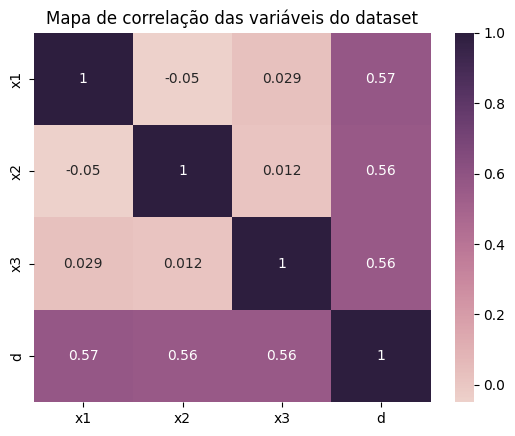

In [15]:
# Gera um gráfico matricial para apresentar a correlação entre as variáveis do dataset
ax = sns.heatmap(df_treino.corr(numeric_only=True), annot=True, cmap=sns.cubehelix_palette(as_cmap=True))
ax.set_title('Mapa de correlação das variáveis do dataset')
ax=ax

Pré-Processamento dos Dados

Aqui não é aplicado StandardScaler() nem MinMaxScaler(). O enunciado informa que o dataset já está normalizado, ou seja, todas as variáveis {x1, x2, x3} e a saída desejada {d} já se encontram no intervalo [0, 1].

Também não é utilizado train_test_split(), pois o conjunto de validação já foi fornecido separadamente pelo enunciado (tabela de 20 amostras).

In [16]:
trainX = df_treino[['x1', 'x2', 'x3']]
trainY = df_treino['d']

testX = df_teste[['x1', 'x2', 'x3']]
testY = df_teste['d']

df_treino.describe()

,x1,x2,x3,d
count,200.000000,200.000000,200.000000,200.000000
mean,0.500101,0.491556,0.482271,0.624440
std,0.306622,0.303002,0.284523,0.180872
min,0.000000,0.000000,0.000000,0.085100
25%,0.240325,0.209325,0.252475,0.492900
50%,0.472850,0.532300,0.462600,0.627250
75%,0.786375,0.757075,0.697900,0.771275
max,1.000000,1.000000,1.000000,0.990400


Item 1 - Aplicação do MLPRegressor nos 9 Treinamentos

Combinação das funções de ativação ('tanh', 'relu', 'logistic') com a quantidade de neurônios da camada oculta (5, 10 e 15), totalizando 9 treinamentos. Em todos eles a taxa de aprendizagem é 0.01 e a quantidade máxima de épocas é 1000, sendo as demais configurações mantidas no padrão do MLPRegressor.

Observação: como os pesos iniciais da rede são sorteados aleatoriamente e nenhuma semente é fixada, os valores de perda final e de épocas mudam a cada nova execução, podendo alterar a ordem do ranking.

In [17]:
ativacoes = ['tanh', 'relu', 'logistic']
neuronios = [5, 10, 15]

resultados = []
modelos = {}
treinamento = 0

for ativacao in ativacoes:
    for n in neuronios:
        treinamento = treinamento + 1
        mlp_reg = MLPRegressor(hidden_layer_sizes=(n), activation=ativacao, solver='adam',
                               learning_rate_init=0.01, max_iter=1000)

        # Execução do treinamento da RNA
        mlp_reg.fit(trainX, trainY)

        modelos['T' + str(treinamento)] = mlp_reg
        resultados.append({'Treinamento': 'T' + str(treinamento),
                           'Neurônios': n,
                           'Ativação': ativacao,
                           'Perda Final': mlp_reg.loss_,
                           'Número de Épocas': mlp_reg.n_iter_})

        print('T' + str(treinamento), '-', n, 'neurônios -', ativacao,
              '- Perda Final:', round(mlp_reg.loss_, 8), '- Épocas:', mlp_reg.n_iter_)

T1 - 5 neurônios - tanh - Perda Final: 0.00059731 - Épocas: 48
T2 - 10 neurônios - tanh - Perda Final: 0.00867237 - Épocas: 19
T3 - 15 neurônios - tanh - Perda Final: 0.00061505 - Épocas: 49
T4 - 5 neurônios - relu - Perda Final: 0.00202681 - Épocas: 115
T5 - 10 neurônios - relu - Perda Final: 0.00071248 - Épocas: 43
T6 - 15 neurônios - relu - Perda Final: 0.00657917 - Épocas: 60
T7 - 5 neurônios - logistic - Perda Final: 0.01464264 - Épocas: 55
T8 - 10 neurônios - logistic - Perda Final: 0.02696656 - Épocas: 35
T9 - 15 neurônios - logistic - Perda Final: 0.02574209 - Épocas: 20


In [18]:
tabela = pd.DataFrame(resultados)
tabela['Ranking'] = tabela['Perda Final'].rank(method='min').astype(int) # Classifica as configurações da menor para a maior perda final
tabela

,Treinamento,Neurônios,Ativação,Perda Final,Número de Épocas,Ranking
0,T1,5,tanh,0.000597,48,1
1,T2,10,tanh,0.008672,19,6
2,T3,15,tanh,0.000615,49,2
3,T4,5,relu,0.002027,115,4
4,T5,10,relu,0.000712,43,3
5,T6,15,relu,0.006579,60,5
6,T7,5,logistic,0.014643,55,7
7,T8,10,logistic,0.026967,35,9
8,T9,15,logistic,0.025742,20,8


In [19]:
ranking = tabela.sort_values('Ranking')
print(ranking.to_string(index=False))

melhor = ranking.iloc[0]
mlp_melhor = modelos[melhor['Treinamento']] # Recupera o modelo treinado da melhor configuração

print('\nMelhor configuração:', melhor['Treinamento'],
      '-', melhor['Neurônios'], 'neurônios na camada oculta com ativação', melhor['Ativação'],
      '- Perda Final:', round(melhor['Perda Final'], 8),
      '- Épocas:', melhor['Número de Épocas'])

Treinamento  Neurônios Ativação  Perda Final  Número de Épocas  Ranking
         T1          5     tanh     0.000597                48        1
         T3         15     tanh     0.000615                49        2
         T5         10     relu     0.000712                43        3
         T4          5     relu     0.002027               115        4
         T6         15     relu     0.006579                60        5
         T2         10     tanh     0.008672                19        6
         T7          5 logistic     0.014643                55        7
         T9         15 logistic     0.025742                20        8
         T8         10 logistic     0.026967                35        9

Melhor configuração: T1 - 5 neurônios na camada oculta com ativação tanh - Perda Final: 0.00059731 - Épocas: 48


Avaliação do Erro no Processo de Treinamento

Comparação da curva de perda dos 9 treinamentos e, na sequência, o gráfico de perda isolado da melhor configuração, conforme solicitado.

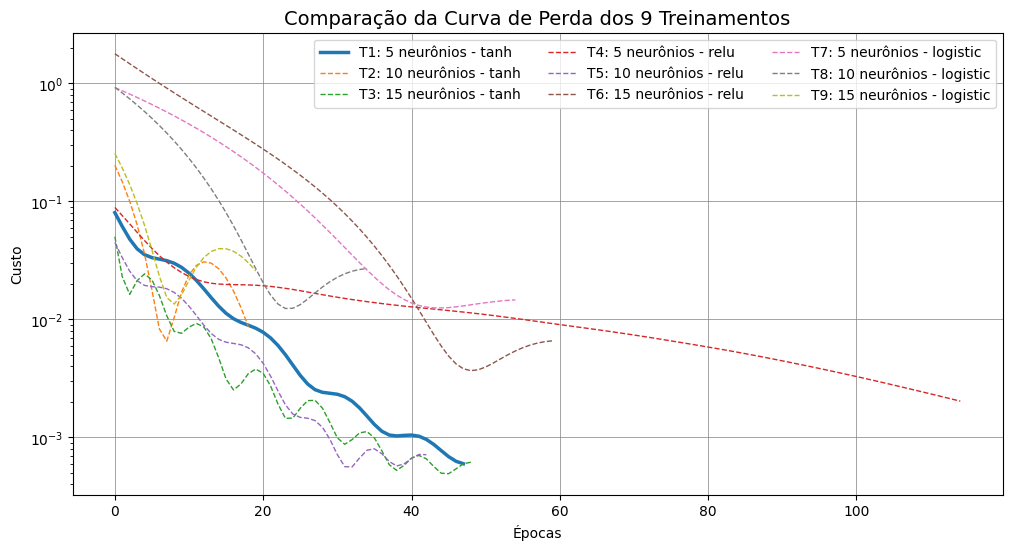

In [20]:
plt.figure(figsize=(12,6))
for chave in modelos:
    linha = tabela[tabela['Treinamento'] == chave].iloc[0]
    plt.plot(modelos[chave].loss_curve_,
             linewidth = 2.5 if chave == melhor['Treinamento'] else 1.0,
             linestyle = '-' if chave == melhor['Treinamento'] else '--',
             label = chave + ': ' + str(linha['Neurônios']) + ' neurônios - ' + linha['Ativação'])

plt.title("Comparação da Curva de Perda dos 9 Treinamentos", fontsize=14)
plt.xlabel('Épocas')
plt.ylabel('Custo')
plt.yscale('log')
plt.legend(ncol=3)
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.show()

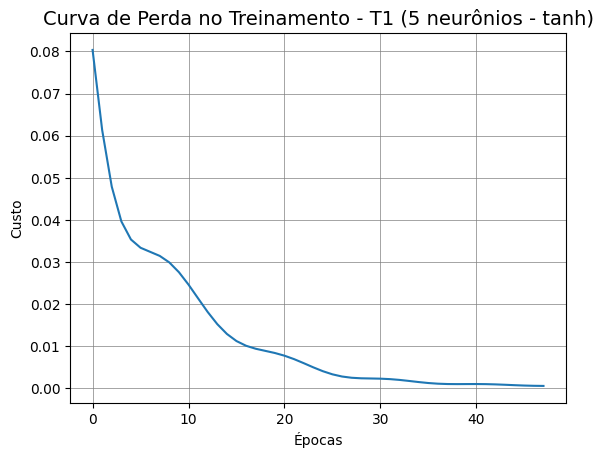

In [21]:
plt.plot(mlp_melhor.loss_curve_) # Plotando o gráfico de erros no processo de treinamento da melhor configuração
plt.title("Curva de Perda no Treinamento - " + melhor['Treinamento'] + " (" + str(melhor['Neurônios']) + " neurônios - " + melhor['Ativação'] + ")", fontsize=14)
plt.xlabel('Épocas')
plt.ylabel('Custo')
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.show()

Item 2 - Avaliação do Modelo na Validação

A melhor configuração obtida no Item 1 é aplicada ao conjunto de teste fornecido no enunciado, composto por 20 amostras que não participaram do treinamento.

In [22]:
y_pred = mlp_melhor.predict(testX)

df_temp = pd.DataFrame({'Desejado': testY, 'Estimado': y_pred})
df_temp.index = df_temp.index + 1
df_temp['Erro Absoluto'] = abs(df_temp['Desejado'] - df_temp['Estimado'])
df_temp['Erro Relativo (%)'] = abs((df_temp['Desejado'] - df_temp['Estimado']) / df_temp['Desejado']) * 100
df_temp

,Desejado,Estimado,Erro Absoluto,Erro Relativo (%)
1,0.4831,0.504299,0.021199,4.388204
2,0.5965,0.609435,0.012935,2.168419
3,0.5318,0.540456,0.008656,1.627772
4,0.6843,0.701997,0.017697,2.586185
5,0.2872,0.315811,0.028611,9.962196
6,0.7663,0.732131,0.034169,4.458926
7,0.5666,0.572475,0.005875,1.036863
8,0.6601,0.676927,0.016827,2.549127
9,0.5427,0.572371,0.029671,5.467223
10,0.5836,0.598381,0.014781,2.532734


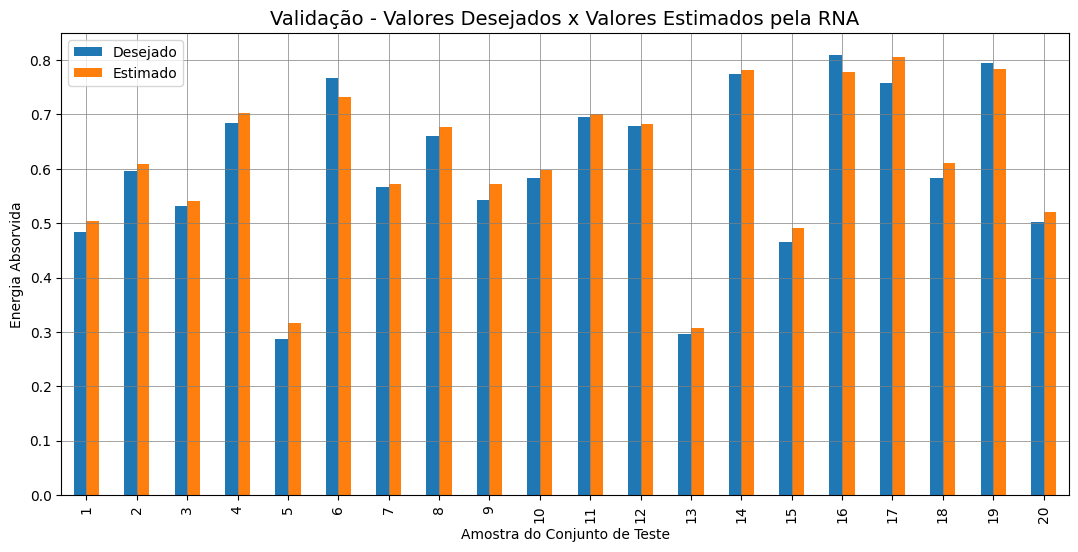

In [23]:
df_temp[['Desejado', 'Estimado']].plot(kind='bar', figsize=(13,6))
plt.title("Validação - Valores Desejados x Valores Estimados pela RNA", fontsize=14)
plt.xlabel('Amostra do Conjunto de Teste')
plt.ylabel('Energia Absorvida')
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='blue')
plt.show() # Apresenta o gráfico comparando o desejado e o estimado pelo modelo neural

In [24]:
print('Mean Absolute Error (MAE):', metrics.mean_absolute_error(testY, y_pred))
print('Mean Squared Error (MSE):', metrics.mean_squared_error(testY, y_pred))
print('Root Mean Squared Error (RMSE):', np.sqrt(metrics.mean_squared_error(testY, y_pred)))
print('Mean Absolute Percentage Error (MAPE):', metrics.mean_absolute_percentage_error(testY, y_pred))
print('R2: ', metrics.r2_score(testY, y_pred)) # Apresenta o R2 Score - Representa quanto o modelo está prevendo corretamente, tem uma variação de 0 a 1. Caso seja obtido pelo modelo o R2 = 1, pode ser afirmado que os dados tem relação linear de 100%.

Mean Absolute Error (MAE): 0.01897794681905417
Mean Squared Error (MSE): 0.0004891530278268618
Root Mean Squared Error (RMSE): 0.022116804195607957
Mean Absolute Percentage Error (MAPE): 0.03413715842982261
R2:  0.9773356393973927


Conclusão

Os valores exatos da melhor configuração e das métricas devem ser lidos das saídas das células acima, referentes a esta execução. Os pontos a observar são:

- Sem semente fixa, o ranking das nove configurações muda de forma significativa a cada execução.
- A origem dessa variação é a inicialização aleatória dos pesos combinada com o critério de parada padrão.
- Por esse mesmo motivo, o número de épocas não deve ser lido como indicador de qualidade. Nenhum treinamento atinge o limite de 1000 épocas, ou seja, todos param pela tolerância.
- Na validação com as 20 amostras inéditas, a rede reproduz o mapeamento {x1, x2, x3} -> y com erro percentual médio baixo e R2 elevado, confirmando a capacidade do MLP de atuar como aproximador universal de funções neste problema.